In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

## Load four lists

In [2]:
sets_df = pd.read_csv("../../../data-public/subreddit_sets.csv")

subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}

matched1_indp = subreddit_sets["matched1_indp"]
matched2_indp= subreddit_sets["matched2_indp"]
matched2_conn = subreddit_sets["matched2_conn"]
random = subreddit_sets["random"]
banned = subreddit_sets["banned"]

samples_df = pd.read_csv(f"{DATAPATH}/data/samples/to_match_table_selfid_banned_3274_260528.csv")
samples_df = samples_df[samples_df["lifetime_d"]>0]
banned_df = samples_df[samples_df["if_banned"]==1]
random_df = samples_df[samples_df["if_banned"]==0].sample(n=len(banned_df), replace=False, random_state=42)

## message #1: suppose we don't restrict overlap and match on lifespan and popularity, matched set will have a lot of connected subreddits sharing many users with banned subreddits.

In [ ]:
conn_list = pd.read_parquet(f"{DATAPATH}/data/counts-raw/n_overlap_user_post_w_banned-2020-3274_thresholded.parquet")
conn_df = pd.DataFrame()
conn_df["subreddit"] = list(matched2_conn)
conn_df = conn_df.merge(
    conn_list[["subreddit","u_overlap_min_post_ban_1"]], on="subreddit", how="left").fillna(0)
conn_df.head()

,subreddit,u_overlap_min_post_ban_1
0,tomomimorisaki,2.0
1,capitolreefnp,1.0
2,projectaresfps,0.0
3,voxpopgames,0.0
4,dicksizephilosophy,26.0


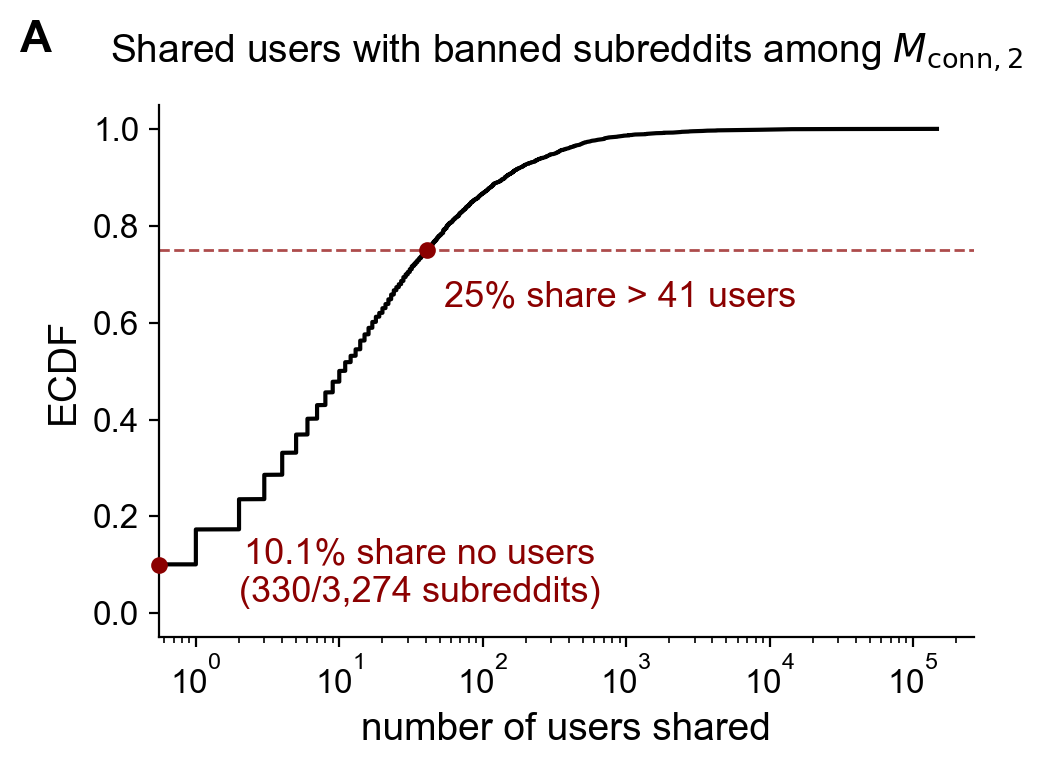

In [24]:
def ecdf(x):
    x = np.sort(np.asarray(x))
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

col = "u_overlap_min_post_ban_1"

vals = conn_df[col].tolist()
x,y = ecdf(vals)
fig, ax = plt.subplots(figsize=(5,4))
ax.plot(x,y, color="black")
ax.set_ylabel("ECDF", fontsize=14)
ax.set_xlabel("number of users shared", fontsize=14)
ax.set_title(
    "Shared users with banned subreddits among "
    # r"$\mathtt{MATCH{-}CONN{-}2COV}$",
    r"$M_{\mathrm{conn},2}$",
    fontsize=14, 
    y=1.05
)
ax.set_xscale("log")

pct_zero = conn_df[col].eq(0).mean() * 100
n_zero = conn_df[col].eq(0).sum()
n_total = conn_df[col].notna().sum()

y_zero = n_zero / n_total
ax.scatter(
    0.0, y_zero,
    transform=ax.get_yaxis_transform(),  # x in axes coords, y in data coords
    color="darkred",
    s=25,
    zorder=5,
    clip_on=False
)

ax.annotate(
    f"{pct_zero:.1f}% share no users\n({n_zero:,}/{n_total:,} subreddits)",
    xy=(0.0, y_zero),                 # left edge of axes, at the zero-mass height
    xycoords=("axes fraction", "data"),
    xytext=(0.32, 0.12),              # move text away from curve
    textcoords="axes fraction",
    ha="center",
    va="center",
    color="darkred",
    fontsize=13,
    # bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5),
    # arrowprops=dict(arrowstyle="->", lw=1, color="black")
)

# 75% point among all non-missing values
q75 = np.quantile(vals, 0.75)

ax.axhline(0.75, color="darkred", lw=1, ls="--", alpha=0.7)
ax.scatter(q75, 0.75, color="darkred", s=25, zorder=5)

ax.annotate(
    f"25% share > {q75:,.0f} users",
    xy=(q75, 0.75),
    xycoords="data",
    xytext=(0.35, 0.64),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=13,
    color="darkred",
    # bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5),
    # arrowprops=dict(arrowstyle="->", lw=1.2, color="darkred")
)
fig.text(
    0.01, 0.96, "A",
    fontsize=16, fontweight="bold",
    ha="left", va="top",
)
plt.tight_layout()

plt.savefig(f"../../../output/appendix/ecdf-overlap-users-matched-conn-2cov.png", dpi=300, bbox_inches="tight")
plt.savefig(f"../../../output/appendix/ecdf-overlap-users-matched-conn-2cov.pdf", dpi=300, bbox_inches="tight")

## message #2: 

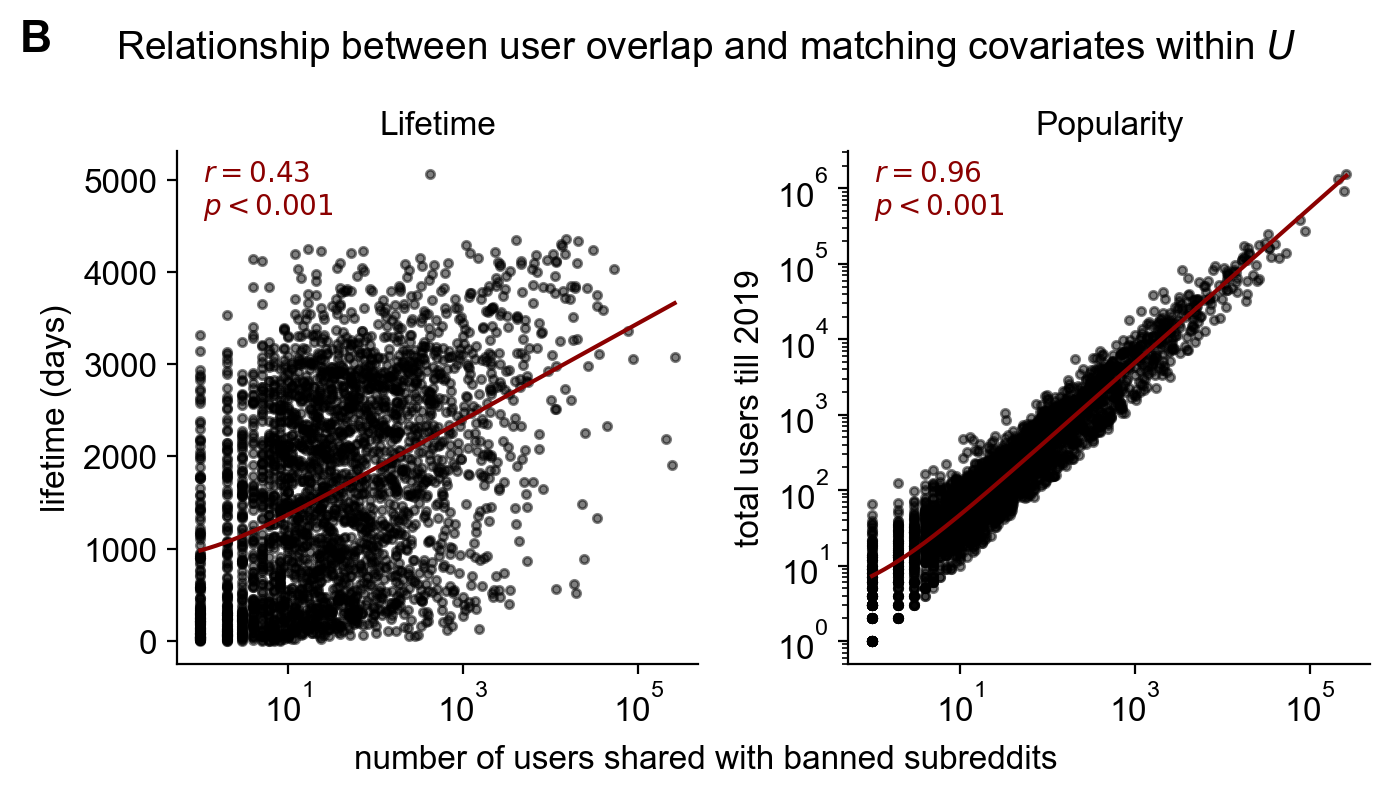

In [11]:
from scipy.stats import pearsonr, linregress

x_col = "u_overlap_min_post_ban_1"
fig, ax = plt.subplots(figsize=(7, 4.2), ncols=2, sharex=True)

# -------------------------
# Panel 1: lifetime
# -------------------------
plot_df = random_df[[x_col, "lifetime_d"]].dropna().copy()
plot_df = plot_df[plot_df[x_col] > 0]

x = plot_df[x_col]
y = plot_df["lifetime_d"]

ax[0].scatter(x, y, color="black", marker=".", alpha=0.5)

log_x = np.log1p(x)

slope, intercept, r_value, p_value, stderr = linregress(log_x, y)

x_grid = np.logspace(np.log10(x.min()), np.log10(x.max()), 300)
y_hat = intercept + slope * np.log1p(x_grid)

ax[0].plot(x_grid, y_hat, color="darkred", lw=1.5)

r, p = pearsonr(log_x, y)

ax[0].text(
    0.05, 0.98,
    rf"$r = {r:.2f}$" + "\n" + rf"$p < 0.001$" if p < 0.001 else rf"$r = {r:.2f}$" + "\n" + rf"$p = {p:.2g}$",
    transform=ax[0].transAxes,
    ha="left",
    va="top",
    fontsize=10,
    color="darkred",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5)
)

ax[0].set_title("Lifetime", fontsize=12)
ax[0].set_ylabel("lifetime (days)", fontsize=12)


# -------------------------
# Panel 2: cumulative users
# -------------------------
plot_df = random_df[[x_col, "n_post_author_till2019"]].dropna().copy()
plot_df = plot_df[(plot_df[x_col] > 0) & (plot_df["n_post_author_till2019"] > 0)]

x = plot_df[x_col]
y = plot_df["n_post_author_till2019"]

ax[1].scatter(x, y, color="black", marker=".", alpha=0.5)

log_x = np.log1p(x)
log_y = np.log1p(y)

slope, intercept, r_value, p_value, stderr = linregress(log_x, log_y)

x_grid = np.logspace(np.log10(x.min()), np.log10(x.max()), 300)
y_hat = np.expm1(intercept + slope * np.log1p(x_grid))

ax[1].plot(x_grid, y_hat, color="darkred", lw=1.5)

r, p = pearsonr(log_x, log_y)

ax[1].text(
    0.05, 0.98,
    rf"$r = {r:.2f}$" + "\n" + rf"$p < 0.001$" if p < 0.001 else rf"$r = {r:.2f}$" + "\n" + rf"$p = {p:.2g}$",
    transform=ax[1].transAxes,
    ha="left",
    va="top",
    fontsize=10,
    color="darkred",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5)
)

ax[1].set_title("Popularity", fontsize=12)
ax[1].set_ylabel("total users till 2019", fontsize=12)
ax[1].set_yscale("log")


# -------------------------
# Shared formatting
# -------------------------
for a in ax:
    a.set_xscale("log")

fig.suptitle(
    "Relationship between user overlap and matching covariates within "
    # r"$\mathtt{RANDOM}$",
    r"$U$",
    fontsize=14,
    y=0.96
)

fig.supxlabel(
    "number of users shared with banned subreddits",
    fontsize=12,
    y=0.07
)
fig.text(
    0.01, 0.97, "B",
    fontsize=16, fontweight="bold",
    ha="left", va="top",
)

plt.tight_layout()
plt.savefig(f"../../../output/appendix/scatter-overlap-matching-covariates-random.png", dpi=300, bbox_inches="tight")
plt.savefig(f"../../../output/appendix/scatter-overlap-matching-covariates-random.pdf", dpi=300, bbox_inches="tight")